СИМВОЛЬНИЙ ВИРАЗ АПРОКСИМУЮЧОЇ ФУНКЦІЇ
P(x) = -0.950279307340226*x**3 + 18.0708123273377*x**2 - 66.088721531966*x + 26.9512637764062

 ПОРІВНЯННЯ ВІДНОВЛЕНИХ ЗНАЧЕНЬ З РЕАЛЬНИМИ
Рік 2014: Фактичне = 13.0 | Відновлене = -34.34 | Абс. похибка = 47.34 | Відн. похибка = 364.1%
Рік 2018: Фактичне = 103.0 | Відновлене = 123.85 | Абс. похибка = 20.85 | Відн. похибка = 20.2%
Рік 2013: Фактичне = 3.0 | Відновлене = -40.55 | Абс. похибка = 43.55 | Відн. похибка = 1451.5%


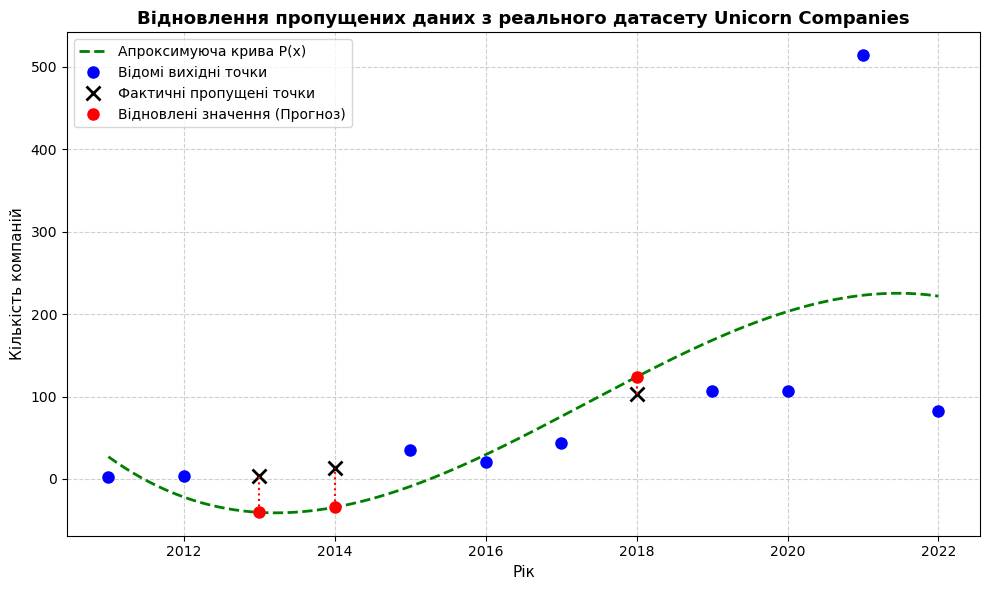

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sympy import symbols
from scipy.optimize import curve_fit

# Завантаження та очищення датасету
df = pd.read_csv('Unicorn_Companies.csv')

# Перетворюємо дату приєднання у формат datetime та витягуємо рік
df['Date Joined'] = pd.to_datetime(df['Date Joined'], errors='coerce')
df['Year_Joined'] = df['Date Joined'].dt.year

# Очищаємо стовпчик Valuation ($B) від знака долара та переводимо у числа
df['Valuation_Num'] = df['Valuation ($B)'].astype(str).str.replace('$', '', regex=False)
df['Valuation_Num'] = df['Valuation_Num'].str.replace('B', '', regex=False)
df['Valuation_Num'] = df['Valuation_Num'].str.replace('M', '', regex=False)
df['Valuation_Num'] = pd.to_numeric(df['Valuation_Num'], errors='coerce')

# Видаляємо пропущені значення в критичних стовпчиках
df_clean = df.dropna(subset=['Year_Joined', 'Valuation_Num']).copy()

# КРОК 1: Групування даних за роками (для нашого графіку)
df_grouped = df_clean.groupby('Year_Joined').size().reset_index(name='Count')
# Фільтруємо період з 2011 по 2022 рік
df_grouped = df_grouped[(df_grouped['Year_Joined'] >= 2011) & (df_grouped['Year_Joined'] <= 2022)]

years = df_grouped['Year_Joined'].values
actual_counts = df_grouped['Count'].values

base_year = years.min()
x_all = years - base_year
y_all = actual_counts.astype(float)

# КРОК 2: Імітація пропуску даних (штучне видалення 3 точок)
np.random.seed(42)
missing_indices = np.random.choice(range(2, len(years) - 2), size=3, replace=False)
known_indices = [i for i in range(len(years)) if i not in missing_indices]

x_known = x_all[known_indices]
y_known = y_all[known_indices]

x_missing = x_all[missing_indices]
y_actual_missing = y_all[missing_indices]
years_missing = years[missing_indices]

# КРОК 3: Апроксимація поліномом 3-го степеня
degree = 3
coefficients = np.polyfit(x_known, y_known, degree)
poly_func = np.poly1d(coefficients)

y_predicted_missing = poly_func(x_missing)

# КРОК 4: Вивід результатів та розрахунок похибок
x_sym = symbols('x')
sympy_poly = sum(c * x_sym**(degree - i) for i, c in enumerate(coefficients))

print("СИМВОЛЬНИЙ ВИРАЗ АПРОКСИМУЮЧОЇ ФУНКЦІЇ")
print(f"P(x) = {sympy_poly}")
print("\n ПОРІВНЯННЯ ВІДНОВЛЕНИХ ЗНАЧЕНЬ З РЕАЛЬНИМИ")
for yr, act, pred in zip(years_missing, y_actual_missing, y_predicted_missing):
    abs_err = abs(act - pred)
    rel_err = (abs_err / act) * 100
    print(f"Рік {yr}: Фактичне = {act} | Відновлене = {pred:.2f} | Абс. похибка = {abs_err:.2f} | Відн. похибка = {rel_err:.1f}%")

# КРОК 5: Візуалізація
plt.figure(figsize=(10, 6))
x_dense = np.linspace(min(x_all), max(x_all), 200)
y_dense = poly_func(x_dense)

plt.plot(x_dense + base_year, y_dense, 'g--', label='Апроксимуюча крива P(x)', linewidth=2)
plt.plot(x_known + base_year, y_known, 'bo', markersize=8, label='Відомі вихідні точки')
plt.plot(years_missing, y_actual_missing, 'kx', markersize=10, markeredgewidth=2, label='Фактичні пропущені точки')
plt.plot(years_missing, y_predicted_missing, 'ro', markersize=8, label='Відновлені значення (Прогноз)')

for yr, act, pred in zip(years_missing, y_actual_missing, y_predicted_missing):
    plt.vlines(x=yr, ymin=min(act, pred), ymax=max(act, pred), colors='red', linestyles='dotted')

plt.title('Відновлення пропущених даних з реального датасету Unicorn Companies', fontsize=13, fontweight='bold')
plt.xlabel('Рік', fontsize=11)
plt.ylabel('Кількість компаній', fontsize=11)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()